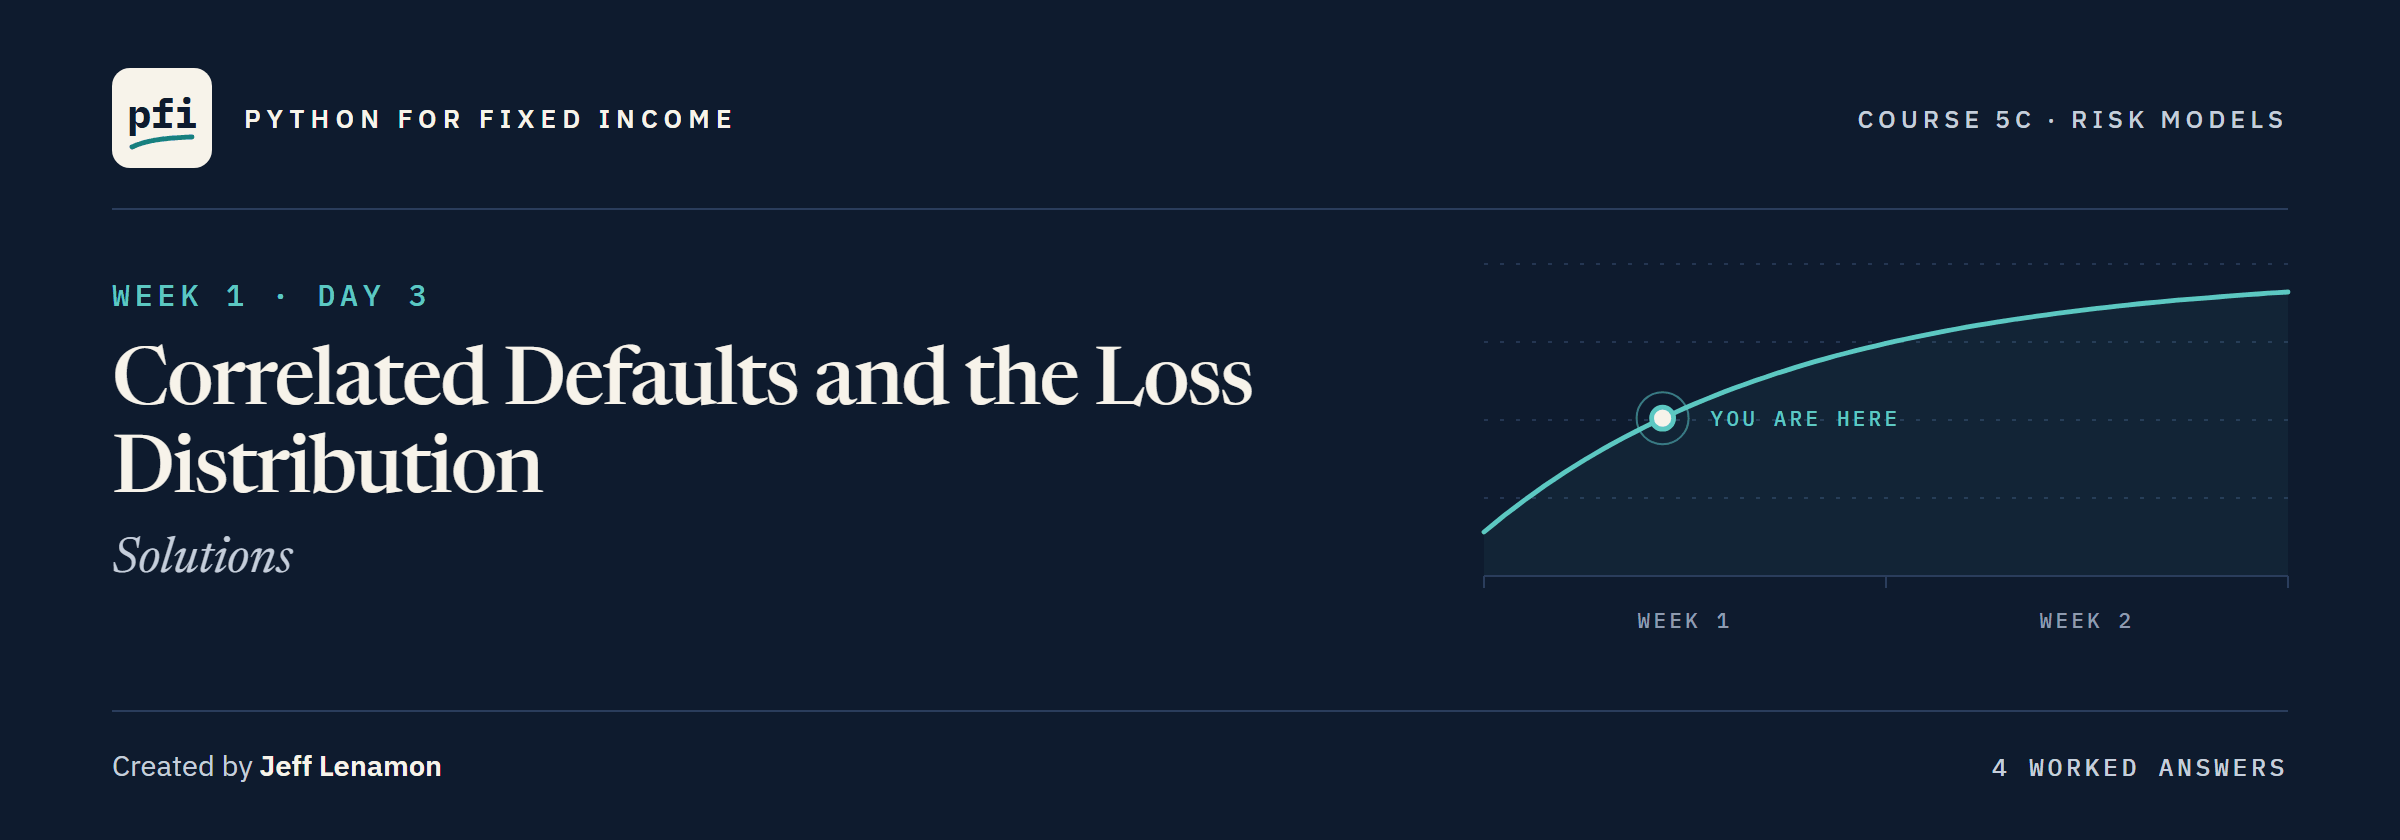

# Correlated Defaults and the Loss Distribution: Solutions

Week 1, Day 3. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `holdings.csv`, the course's book of 200 bonds as of 2026-09-30, with `ratings.csv` for the rating scale: **synthetic**, invented issuers and CUSIPs, no real company.

**Data:** `course5c_cohort.csv`, 4,000 invented firms followed year by year over 20 study years to default, exit, or the end: **synthetic**, ids only, no calendar years, and no agency default statistic.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week1/day3/03_correlated_defaults_and_the_loss_distribution_solutions.ipynb)

# Problem Statement

## Business Context

A credit risk team holds the course's book, 200 bonds from 115 issuers worth US$490.8m as of 2026-09-30.
Day 2 replayed market moves on it; today asks how a year's credit loss from defaults is spread.
That needs a default rate for every rating, counted from a cohort of 4,000 invented firms followed over study years, and a way for defaults to arrive together.
A simulated loss holds under these fitted default probabilities, this invented correlation and this invented LGD, never what the book will or can lose.
The cohort's development years 1 to 14 are fixed before any rate is counted; years 15 to 20 stay closed until the capstone.
The book carries no dates, so it has no split.

## Objectives

Count default rates per firm-year by rating, and bound a rate where none was counted.
Fill thin buckets with one pooled logistic fit and give each bond a default probability.
Compare yearly default counts with what independence allows.
Simulate defaults through one common factor, turn its correlation, and check the simulation against the Vasicek formula.
Simulate the book's credit loss, read its VaR and expected shortfall with their precision, and find where its tail sits.
Correlate two factors with a Cholesky factor, and recognise a matrix that has none.

## Data Dictionary

`course5c_cohort.csv`, one row per firm per study year (the columns used today):

1. `firm_id`: the firm, an invented id
2. `study_year`: 1 to 20, never a calendar year
3. `rating` and `rating_score`: the rating at the start of the year, scored 1 (AAA) to 18 (CCC)
4. `default`: 1 in the year the firm defaulted
5. `exit`: 1 in the year the firm left for a reason unrelated to default

`years_since_entry`, `sector`, `leverage` and `coverage` wait for Days 4 and 5.
`holdings.csv` gives each bond's `cusip`, `issuer`, `sector`, `rating` and `market_value` (US$); `ratings.csv` adds `score`, `bucket` and `grade`.

Made here: `development` (study years 1 to 14), `default_prob` (the pooled fit's default probability, a year), `defaults` (scenarios x bonds), `lgd`, and `losses` (US$ a year, a loss positive).

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# the normal, Student's t and binomial curves, and the logistic fit (Course 4's Day 6)
from scipy import stats
import statsmodels.api as sm

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

# Loading the Data

## Reading the Cohort

In [3]:
# the synthetic cohort: one row per firm per study year
cohort = pd.read_csv(DATA + "course5c_cohort.csv")
print(cohort.shape, "| firms:", cohort["firm_id"].nunique(), "| study years", cohort["study_year"].min(), "to", cohort["study_year"].max())

(29615, 10) | firms: 4000 | study years 1 to 20


## Fixing the Development Years First

In [4]:
# the development study years, fixed before any rate is counted; the later years are counted and left alone
DEVELOPMENT_END = 14
development = cohort[cohort["study_year"] <= DEVELOPMENT_END].copy()
print("Development firm-years:", len(development), "| firms:", development["firm_id"].nunique(),
      "| defaults:", development["default"].sum(), "| exits:", development["exit"].sum())
print("Held-out firm-years:", len(cohort) - len(development))

Development firm-years: 18503 | firms: 3504 | defaults: 345 | exits: 1231
Held-out firm-years: 11112


**Every rate today comes from study years 1 to 14; the later years stay closed until the capstone.**

## Reading the Book and the Rating Scale

In [5]:
# the book of 200 synthetic bonds as of 2026-09-30, and the rating scale
book = pd.read_csv(DATA + "holdings.csv")
ratings = pd.read_csv(DATA + "ratings.csv")

# each bond's score, bucket and grade, and each firm-year's bucket, matched on the rating
book = book.merge(ratings[["rating", "score", "bucket", "grade"]], on="rating")
development = development.merge(ratings[["rating", "bucket"]], on="rating")
print(book.shape, "| market value (US$):", round(book["market_value"].sum()))

(200, 22) | market value (US$): 490819215


# Data Overview

## Missing and Repeated Firm-Years

In [6]:
# blanks, and any firm-year repeated
print("Blanks:", development.isna().sum().sum(), "| repeated firm-years:", development.duplicated(["firm_id", "study_year"]).sum())

Blanks: 0 | repeated firm-years: 0


## One Row, One Firm, One Year

A **firm-year** is one firm watched for one study year: a firm watched for six years counts six.

In [7]:
# the first firm, year by year
development[development["firm_id"] == "F0001"][["firm_id", "study_year", "rating", "default", "exit"]]

,firm_id,study_year,rating,default,exit
0,F0001,1,BB,0,0
1,F0001,2,BB,0,0
2,F0001,3,BB,0,0
3,F0001,4,BB,0,0
4,F0001,5,BB,0,0
5,F0001,6,BB,0,0
6,F0001,7,BB,0,0
7,F0001,8,BB,0,0
8,F0001,9,BB,0,1


In [8]:
# a default or an exit comes only in a firm's last development row
last = development["study_year"] == development.groupby("firm_id")["study_year"].transform("max")
print("Defaults before a firm's last row:", ((development["default"] == 1) & ~last).sum(), "| exits before it:", ((development["exit"] == 1) & ~last).sum())

Defaults before a firm's last row: 0 | exits before it: 0


A firm leaves the file in the year it defaults or exits; Day 4 takes up the exits.

## Firm-Years by Rating Bucket

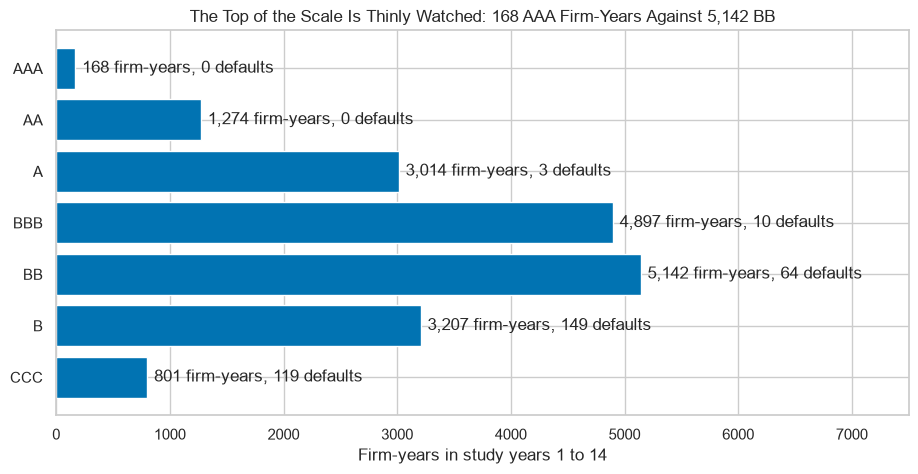

In [9]:
# firm-years and defaults in each bucket, AAA at the top
BUCKETS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC"]
counts = development.groupby("bucket")["default"].agg(["size", "sum"]).loc[BUCKETS]
plt.figure(figsize=(11, 5))
plt.barh(BUCKETS[::-1], counts["size"][::-1])
for i, bucket in enumerate(BUCKETS[::-1]):
    plt.text(counts.loc[bucket, "size"] + 60, i, f"{counts.loc[bucket, 'size']:,} firm-years, {counts.loc[bucket, 'sum']} defaults", va="center")
plt.xlim(0, 7_500)
plt.xlabel("Firm-years in study years 1 to 14")
plt.title("The Top of the Scale Is Thinly Watched: 168 AAA Firm-Years Against 5,142 BB")
plt.show()

BB holds the most firm-years, 5,142; AAA holds 168 and AA 1,274.

**The top of the scale is watched least and defaults least, so its rate rests on the fewest firm-years.**

# Default Rates by Rating

## Counting Defaults per Firm-Year

A **default rate** is defaults over firm-years, in percent a year.

In [10]:
# each bucket's default rate in percent a year, and the rate over all buckets
rates = counts.rename(columns={"size": "firm_years", "sum": "defaults"})
rates["rate_pct"] = 100 * rates["defaults"] / rates["firm_years"]
print("All buckets:", round(100 * development["default"].mean(), 2), "percent a year")
rates.round(2)

All buckets: 1.86 percent a year


,firm_years,defaults,rate_pct
bucket,,,
AAA,168,0,0.00
AA,1274,0,0.00
A,3014,3,0.10
BBB,4897,10,0.20
BB,5142,64,1.24
B,3207,149,4.65
CCC,801,119,14.86


The counted default rate of these invented firms in study years 1 to 14 climbs with every bucket from A down, to 14.86 percent a year in CCC.

AAA and AA counted none.

## The Low-Default Problem

The **low-default problem**: where defaults are rare and firm-years few, a bucket can count none.
A count of zero is not a chance of zero.

**Predict 1**

AAA counted 0 defaults in 168 firm-years.

Q. What is the largest yearly default rate under which 0 in 168 still had at least a 5 percent chance? Write down a percent.

## A Bound From Zero Defaults

At a true rate p, n independent firm-years see no default with chance (1 - p) ** n.
The largest p that keeps that chance at 5 percent is `1 - 0.05 ** (1 / n)`, a **zero-default bound**.

In [11]:
# the bound for each bucket with no default, checked with the binomial's chance of 0 (Course 5's Day 2)
for bucket in ["AAA", "AA"]:
    n = rates.loc[bucket, "firm_years"]
    bound = 1 - 0.05 ** (1 / n)
    print(f"{bucket}: {n:,} firm-years | bound {100 * bound:.3f} percent a year | chance of 0 at the bound {stats.binom.pmf(0, n, bound):.3f} | 3 / n {100 * 3 / n:.3f}")

AAA: 168 firm-years | bound 1.767 percent a year | chance of 0 at the bound 0.050 | 3 / n 1.786
AA: 1,274 firm-years | bound 0.235 percent a year | chance of 0 at the bound 0.050 | 3 / n 0.235


The **rule of three**, 3 / n, lands close to the bound.

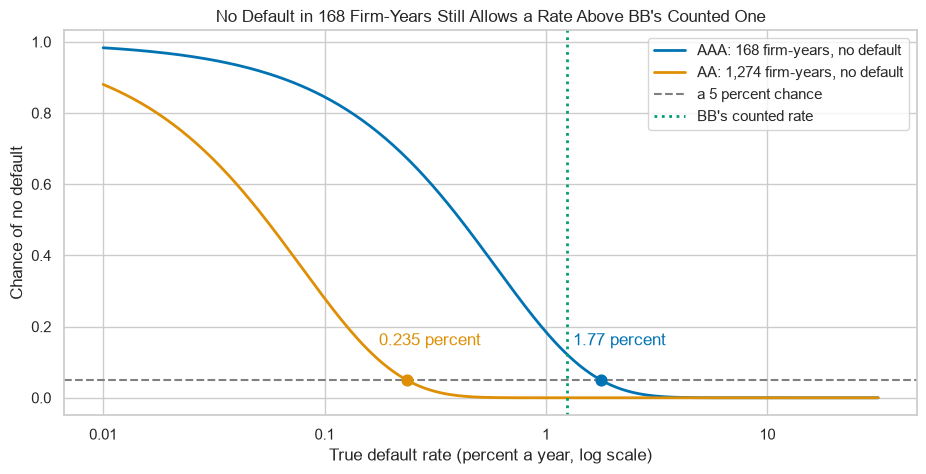

In [12]:
# the chance of no default in n firm-years, (1 - p) ** n, against the true rate p on a log axis
p = np.logspace(-4, -0.5, 300)
plt.figure(figsize=(11, 5))
for bucket, colour in [("AAA", "C0"), ("AA", "C1")]:
    n = rates.loc[bucket, "firm_years"]
    bound = 1 - 0.05 ** (1 / n)
    plt.plot(100 * p, (1 - p) ** n, color=colour, linewidth=2, label=f"{bucket}: {n:,} firm-years, no default")
    plt.scatter(100 * bound, 0.05, color=colour, s=60, zorder=3)
    plt.annotate(f"{100 * bound:.3g} percent", (100 * bound, 0.05), xytext=(-20, 25), textcoords="offset points", color=colour)
plt.axhline(0.05, color="gray", linestyle="--", label="a 5 percent chance")
plt.axvline(rates.loc["BB", "rate_pct"], color="C2", linestyle=":", linewidth=2, label="BB's counted rate")
plt.xscale("log")
plt.xticks([0.01, 0.1, 1, 10], ["0.01", "0.1", "1", "10"])
plt.xlabel("True default rate (percent a year, log scale)")
plt.ylabel("Chance of no default")
plt.title("No Default in 168 Firm-Years Still Allows a Rate Above BB's Counted One")
plt.legend()
plt.show()

AAA's bound, 1.77 percent a year, sits above BB's counted 1.24.

**A bucket with no default only caps its rate, and loosely; a model has to borrow from the buckets that have defaults.**

## One Logistic Line Across the Scale

A **pooled fit** puts every firm-year in one logistic regression of a default in the year on the rating score (Course 4's Day 6).

In [13]:
# one logistic line through all 18,503 firm-years: the log odds of a default in the year on the rating score
X = sm.add_constant(development[["rating_score"]])
pooled = sm.Logit(development["default"], X).fit(disp=0)

# the odds ratio of a default in that year for one notch down the scale
print("Odds ratio a notch:", round(np.exp(pooled.params["rating_score"]), 2))
pd.DataFrame({"coefficient": pooled.params, "standard error": pooled.bse}).round(4)

Odds ratio a notch: 1.64


,coefficient,standard error
const,-10.4489,0.3564
rating_score,0.4967,0.0234


### Interpretation of the Slope

One notch down the scale goes with odds of a default in that year 1.64 times as high: an association in this file.

In [14]:
# the fitted default probability at each notch, percent a year, shown at the notch that names each bucket
scale = ratings[["rating", "score", "bucket"]].copy()
scale["fitted_pct"] = 100 * pooled.predict(sm.add_constant(scale[["score"]].rename(columns={"score": "rating_score"})))
scale[scale["rating"] == scale["bucket"]].round(4)

,rating,score,bucket,fitted_pct
0,AAA,1,AAA,0.0048
2,AA,3,AA,0.0129
5,A,6,A,0.0571
8,BBB,9,BBB,0.2527
11,BB,12,BB,1.1119
14,B,15,B,4.7532
17,CCC,18,CCC,18.1324


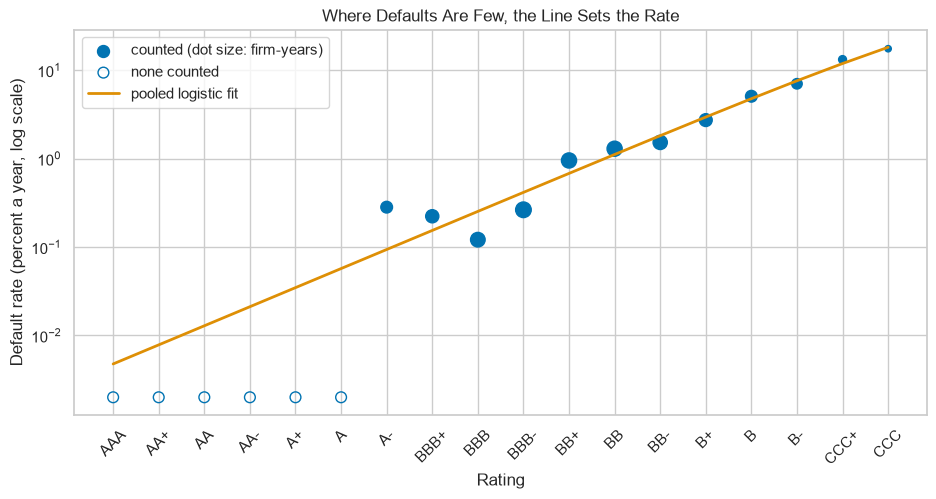

In [15]:
# the counted rate by notch (hollow at the bottom where none was counted) and the fitted line, on a log axis
by_notch = development.groupby("rating_score")["default"].agg(["size", "sum"])
by_notch["rate_pct"] = 100 * by_notch["sum"] / by_notch["size"]
counted = by_notch[by_notch["sum"] > 0]
plt.figure(figsize=(11, 5))
plt.scatter(counted.index, counted["rate_pct"], s=counted["size"] / 15, color="C0", label="counted (dot size: firm-years)")
plt.scatter(by_notch.index[by_notch["sum"] == 0], np.full((by_notch["sum"] == 0).sum(), 0.002), s=60, facecolors="none", edgecolors="C0", label="none counted")
plt.plot(scale["score"], scale["fitted_pct"], color="C1", linewidth=2, label="pooled logistic fit")
plt.yscale("log")
plt.xticks(scale["score"], scale["rating"], rotation=45)
plt.xlabel("Rating")
plt.ylabel("Default rate (percent a year, log scale)")
plt.title("Where Defaults Are Few, the Line Sets the Rate")
plt.legend()
plt.show()

From BB+ down the dots sit close to the line.

From AAA to A no notch counted a default, so there the line alone gives the rate.

## A Default Probability for Every Bond

Each bond takes the pooled fit's default probability for its rating.
`LGD_MEAN` is an input chosen for the lesson, Day 1's 60 percent.

In [16]:
# each bond's default probability for the year, from the pooled fit at its rating score
book["default_prob"] = pooled.predict(sm.add_constant(book[["score"]].rename(columns={"score": "rating_score"})))
print(f"Default probability: {100 * book['default_prob'].min():.4f} to {100 * book['default_prob'].max():.2f} percent a year | mean {100 * book['default_prob'].mean():.2f}")
print("Defaults a year on average:", round(book["default_prob"].sum(), 2))

Default probability: 0.0048 to 18.13 percent a year | mean 1.17
Defaults a year on average: 2.34


In [17]:
# Day 1's expected loss, PD x LGD x EAD, for every bond, in US$
LGD_MEAN = 0.60
book["expected_loss"] = book["default_prob"] * LGD_MEAN * book["market_value"]
grade = book.groupby("grade")[["market_value", "expected_loss"]].sum()
print("Expected loss (US$):", round(book["expected_loss"].sum()))
(grade / grade.sum()).round(4)

Expected loss (US$): 3482412


,market_value,expected_loss
grade,,
High Yield,0.3462,0.9051
Investment Grade,0.6538,0.0949


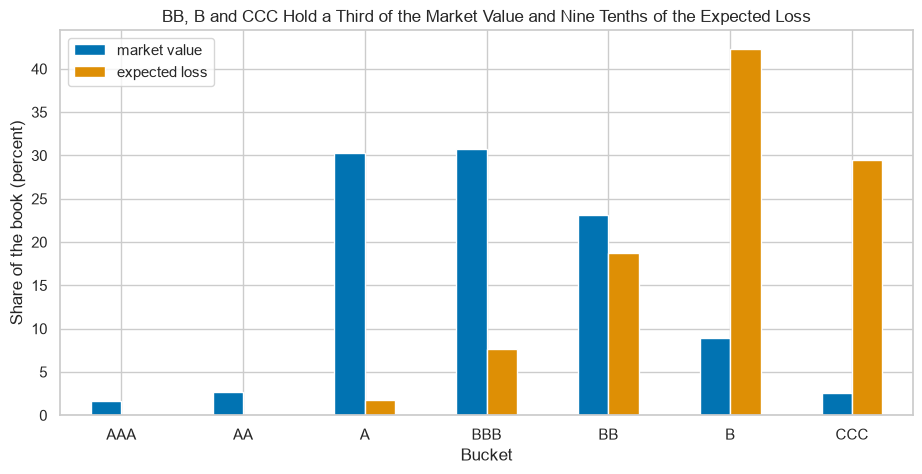

In [18]:
# each bucket's share of the market value against its share of the expected loss
shares = book.groupby("bucket")[["market_value", "expected_loss"]].sum().loc[BUCKETS]
(100 * shares / shares.sum()).plot(kind="bar", figsize=(11, 5), rot=0)
plt.xlabel("Bucket")
plt.ylabel("Share of the book (percent)")
plt.title("BB, B and CCC Hold a Third of the Market Value and Nine Tenths of the Expected Loss")
plt.legend(["market value", "expected loss"])
plt.show()

High yield holds 34.6 percent of the market value and 90.5 percent of the expected loss; investment grade holds 9.5 percent of it.

**Under these inputs the book's expected credit loss is US$3.48m a year; next, how it is spread.**

# Defaults Year by Year

## Each Study Year Against an Independent Band

The pooled fit gives each firm-year a probability, so a study year's fitted count is their sum.
If the firms defaulted independently, the count would spread by sqrt(sum of p(1 - p)), Course 5's Day 2 binomial spread with one p per firm-year.
A **95 percent band** is the fitted count plus or minus 1.96 of those spreads.

**Predict 2**

About 1 year in 20 should land outside a 95 percent band.

Q. Of the 14 development years, how many land outside it? Write down a number.

## Counting the Years Outside

In [19]:
# each study year's counted and fitted defaults, and the spread independence allows
development["fitted"] = pooled.predict(X)
years = development.groupby("study_year").agg(counted=("default", "sum"), fitted=("fitted", "sum"))
years["sd"] = np.sqrt((development["fitted"] * (1 - development["fitted"])).groupby(development["study_year"]).sum())

# each year's gap in those spreads: beyond 1.96 either way, outside the band
z = (years["counted"] - years["fitted"]) / years["sd"]
print("Years outside the band:", list(years.index[z.abs() > 1.96]), "| that is", (z.abs() > 1.96).sum(), "of the 14")

# the average squared gap: about 1 if the firms defaulted independently
print("Average squared gap:", round((z ** 2).mean(), 2))

Years outside the band: [10, 11, 12] | that is 3 of the 14
Average squared gap: 2.17


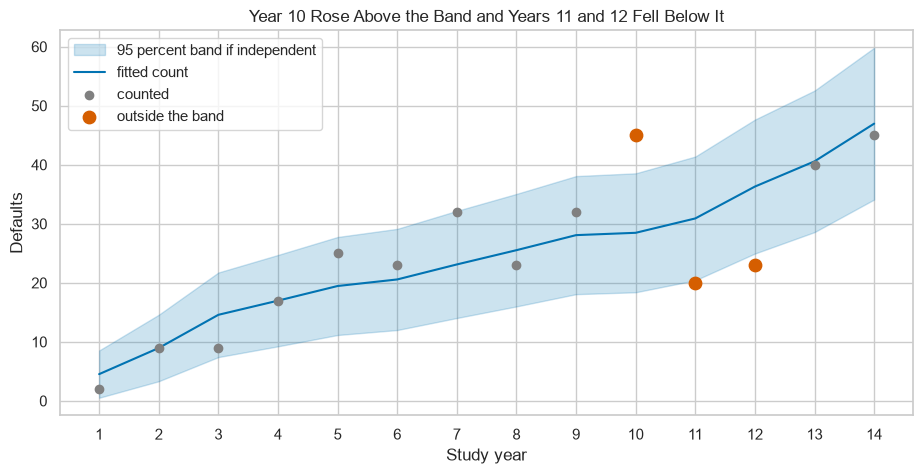

In [20]:
# the counted defaults inside the band independence allows, the years outside marked
outside = z.abs() > 1.96
plt.figure(figsize=(11, 5))
plt.fill_between(years.index, years["fitted"] - 1.96 * years["sd"], years["fitted"] + 1.96 * years["sd"], color="C0", alpha=0.2, label="95 percent band if independent")
plt.plot(years.index, years["fitted"], color="C0", label="fitted count")
plt.scatter(years.index, years["counted"], color="gray", zorder=3, label="counted")
plt.scatter(years.index[outside], years["counted"][outside], color="C3", s=80, zorder=4, label="outside the band")
plt.xticks(years.index)
plt.xlabel("Study year")
plt.ylabel("Defaults")
plt.title("Year 10 Rose Above the Band and Years 11 and 12 Fell Below It")
plt.legend()
plt.show()

### Interpretation of the Band

**Default clustering**: defaults arrived together in some study years and stayed away in others.

The squared gaps averaged 2.17, where independence gives about 1.

The generator shares one draw a study year across every firm (`DATA.md`); the file does not record why a year was bad.

**Defaults arrived together; a model of the book needs one thing every firm shares.**

# The One-Factor Model

## A Common Factor and a Bond's Own

The **one-factor model** gives each bond an **asset value**, a standard normal draw mixed from two parts:

* a **common factor** Z, one draw a scenario shared by every bond;
* an **own factor** e, one draw a scenario for each bond.

The **asset correlation** `rho` sets the mix, `sqrt(rho) * Z + sqrt(1 - rho) * e`, and any two bonds' asset values are correlated `rho`.
The bond defaults when its asset value falls below its **default threshold**, `stats.norm.ppf(default_prob)`: Day 1's -2.0537 is the threshold at 2 percent.

![One common factor Z, drawn once a scenario, feeds every bond's asset value through sqrt(rho); each bond's own factor e feeds only its own asset value through sqrt(1 - rho). The bond defaults when its asset value falls below its default threshold, so a bad draw of Z pulls every asset value down at once](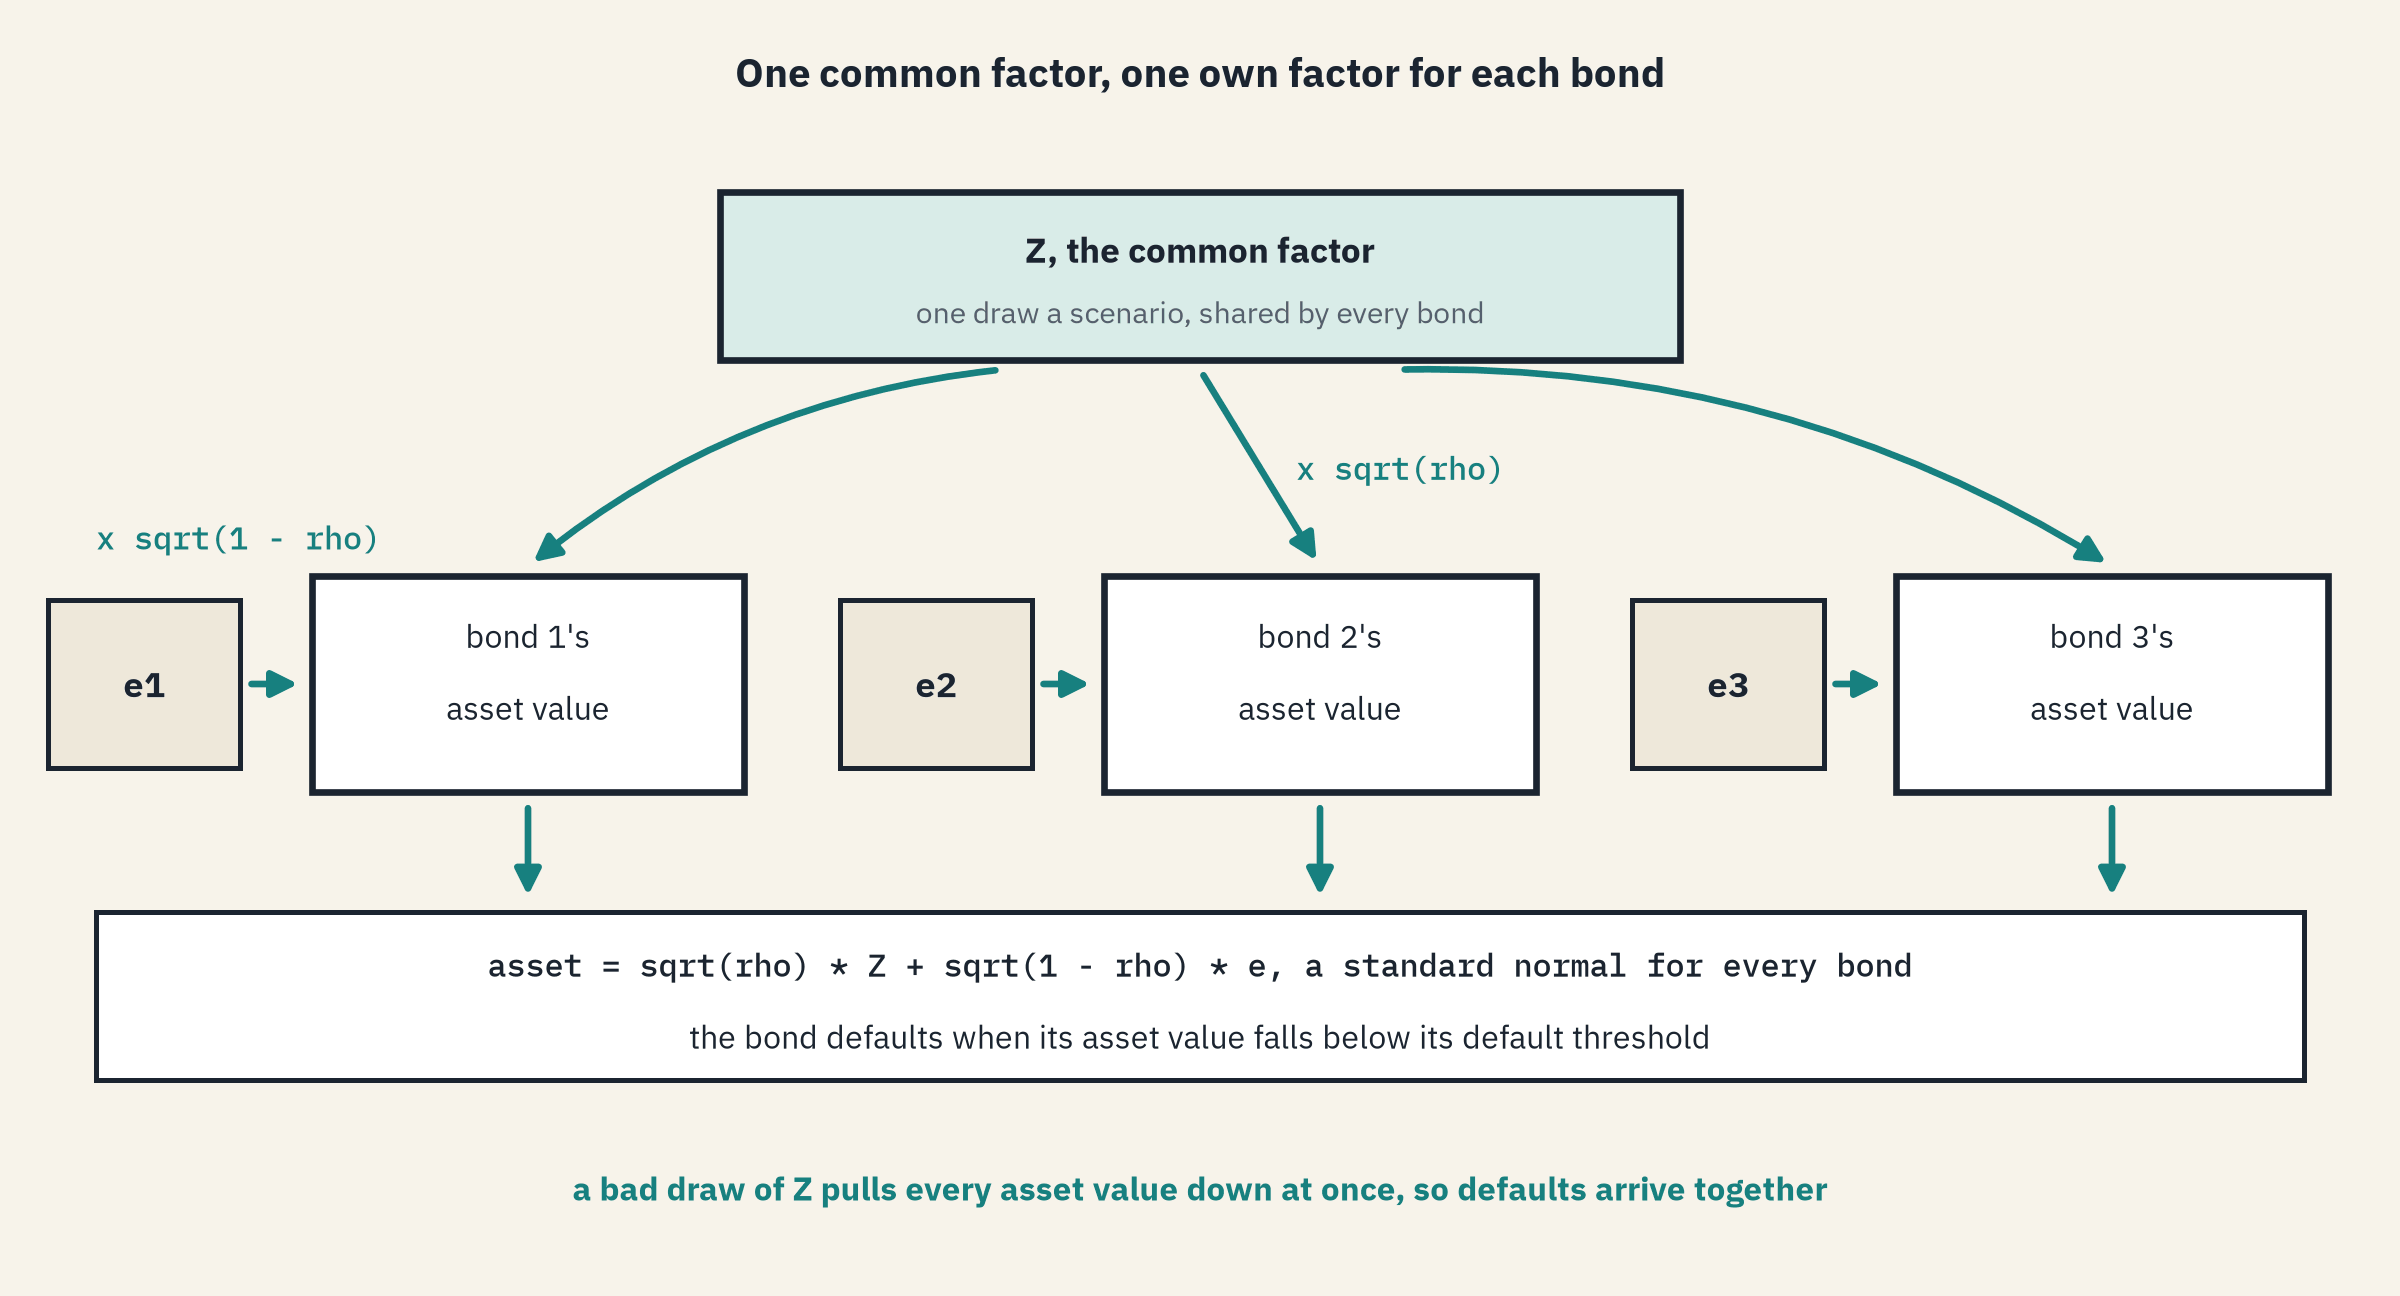)

The mix keeps a standard deviation of 1, so each bond keeps its own default rate.

**Predict 3**

Two bonds each default in 5 percent of years; if independent, both default in 0.25 percent.

Q. At `rho` 0.5, in what percent of years do both default? Write down a percent.

## Two Bonds at 5 Percent

In [21]:
# two bonds at 5 percent, 100,000 scenarios at rho 0 and 0.5, each rho from its own child of SEED
threshold = stats.norm.ppf(0.05)
pair_assets = {}
for rho, rng in zip([0.0, 0.5], np.random.default_rng(SEED).spawn(2)):
    common = rng.standard_normal((100_000, 1))
    own = rng.standard_normal((100_000, 2))
    pair_assets[rho] = np.sqrt(rho) * common + np.sqrt(1 - rho) * own

In [22]:
# each bond alone, and both together, with Day 1's standard error, in percent of scenarios
for rho, assets in pair_assets.items():
    both = (assets < threshold).all(axis=1)
    print(f"rho {rho}: each alone {(100 * (assets < threshold).mean(axis=0)).round(2)} | both {100 * both.mean():.3f} (standard error {100 * both.std(ddof=1) / np.sqrt(len(both)):.3f})")

rho 0.0: each alone [5.02 4.98] | both 0.259 (standard error 0.016)
rho 0.5: each alone [5.   4.96] | both 1.236 (standard error 0.035)


Each bond still defaults in about 5 percent of scenarios at either `rho`.

At `rho` 0.5 both default in 1.236 percent, 4.9 times the independent 0.25.

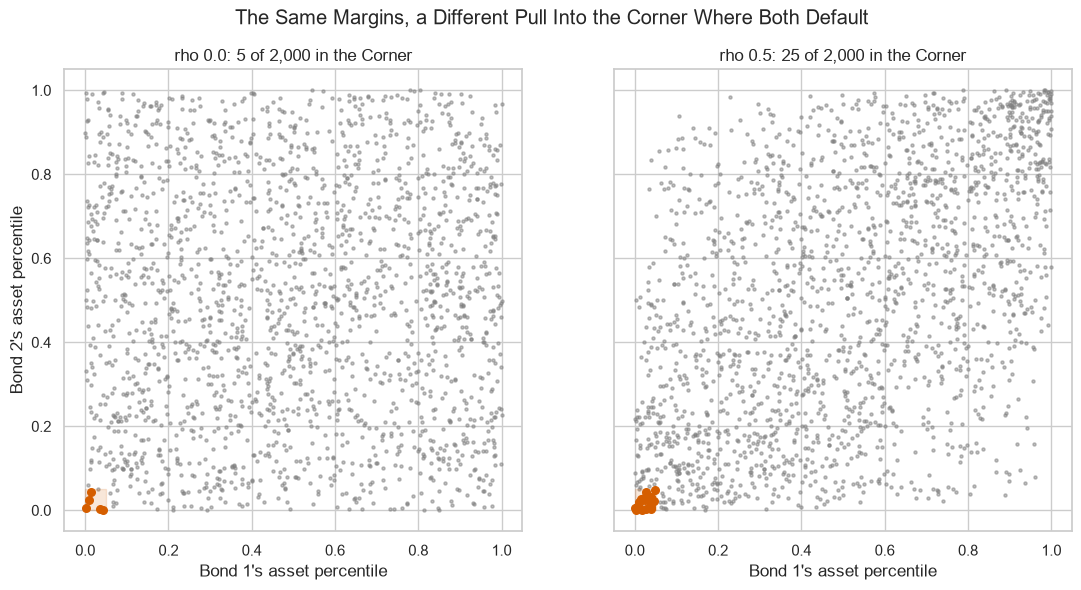

In [23]:
# each asset value read as its percentile with stats.norm.cdf, the first 2,000 scenarios, the both-default corner lit
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
for ax, (rho, assets) in zip(axes, pair_assets.items()):
    u = stats.norm.cdf(assets[:2_000])
    corner = (u < 0.05).all(axis=1)
    ax.scatter(u[:, 0], u[:, 1], s=5, color="gray", alpha=0.5)
    ax.scatter(u[corner, 0], u[corner, 1], s=30, color="C3")
    ax.add_patch(plt.Rectangle((0, 0), 0.05, 0.05, color="C3", alpha=0.15))
    ax.set(title=f"rho {rho}: {corner.sum()} of 2,000 in the Corner", xlabel="Bond 1's asset percentile")
axes[0].set_ylabel("Bond 2's asset percentile")
fig.suptitle("The Same Margins, a Different Pull Into the Corner Where Both Default")
plt.show()

`stats.norm.cdf` puts each axis on its percentile, so each margin stays flat and the picture shows only how the two move together: a **copula**.

## The Same Lines as a Function

In [24]:
# the one-factor draw as a function: the common factor's (n_sims, 1) shape is the whole of the correlation
def one_factor_defaults(default_prob, rho, n_sims, rng):
    """Defaults in each scenario (rows) for each bond (columns), through one common factor."""
    common = rng.standard_normal((n_sims, 1))
    own = rng.standard_normal((n_sims, len(default_prob)))
    return np.sqrt(rho) * common + np.sqrt(1 - rho) * own < stats.norm.ppf(default_prob)

**Correlation leaves each bond's own rate alone and makes bonds fail together.**

# The Correlation Setting

**Predict 4**

One hundred invented bonds, alike, each at 2 percent a year: by the binomial, none defaults in 13.3 percent of years.

Q. At `rho` 0.4, in what percent of years does none default? Write down a percent.

## One Hundred Bonds at Four Correlations

In [25]:
# 50,000 scenarios at each rho, each from its own child of SEED: the count of defaults among the 100 bonds
RHOS = [0.0, 0.1, 0.2, 0.4]
sweep = {}
for rho, child in zip(RHOS, np.random.default_rng(SEED).spawn(4)):
    sweep[rho] = one_factor_defaults(np.full(100, 0.02), rho, 50_000, child).sum(axis=1)

# the mean count, its spread, and the shares with none and with 10 or more, each with its standard error
rows = {}
for rho, count in sweep.items():
    no_default, ten_plus, root_n = count == 0, count >= 10, np.sqrt(len(count))
    rows[rho] = {"mean": count.mean(), "se mean": count.std(ddof=1) / root_n, "sd": count.std(),
                 "none (%)": 100 * no_default.mean(), "se none": 100 * no_default.std(ddof=1) / root_n,
                 "10 or more (%)": 100 * ten_plus.mean(), "se 10 or more": 100 * ten_plus.std(ddof=1) / root_n}
table = pd.DataFrame(rows).T

# the binomial's exact shares at rho 0
print(f"Exact at rho 0: none {100 * stats.binom.pmf(0, 100, 0.02):.2f} percent | 10 or more {100 * stats.binom.sf(9, 100, 0.02):.4f} percent")
table.round(3)

Exact at rho 0: none 13.26 percent | 10 or more 0.0034 percent


,mean,se mean,sd,none (%),se none,10 or more (%),se 10 or more
0.0,2.007,0.006,1.399,13.180,0.151,0.000,0.000
0.1,2.003,0.010,2.185,27.016,0.199,1.166,0.048
0.2,2.008,0.013,3.011,38.356,0.217,3.098,0.077
0.4,1.996,0.021,4.628,56.424,0.222,5.432,0.101


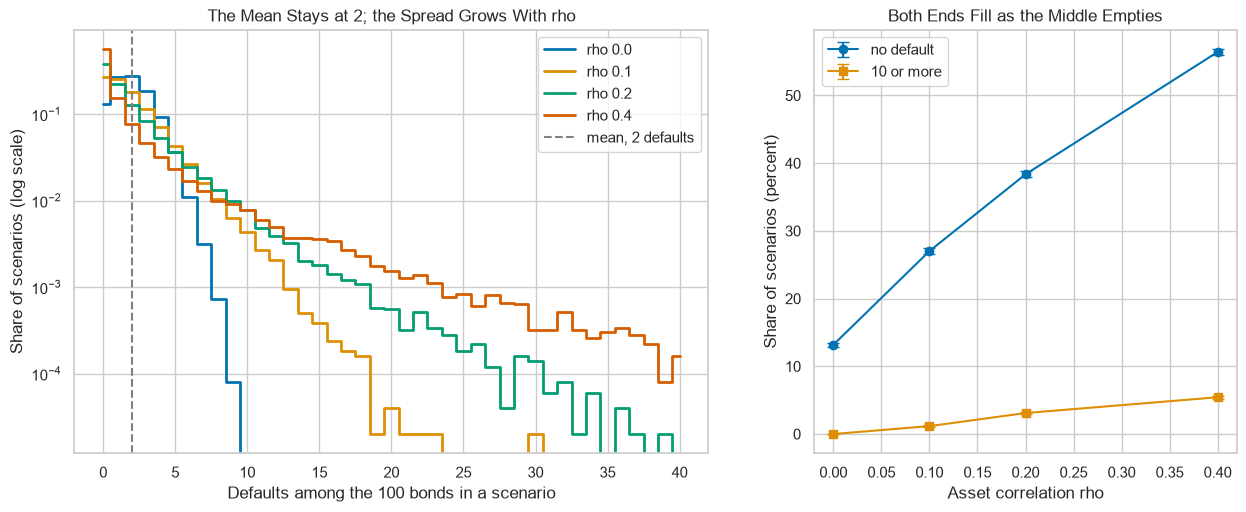

In [26]:
# left: the share of scenarios with each count, one step line per rho, the mean dashed; right: none and 10 or more against rho
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 5.5), width_ratios=[3, 2])
k = np.arange(0, 41)
for rho, counts_rho in sweep.items():
    left.step(k, [np.mean(counts_rho == j) for j in k], where="mid", linewidth=2, label=f"rho {rho}")
left.axvline(2, color="gray", linestyle="--", label="mean, 2 defaults")
left.set(yscale="log", xlabel="Defaults among the 100 bonds in a scenario", ylabel="Share of scenarios (log scale)", title="The Mean Stays at 2; the Spread Grows With rho")
left.legend()
right.errorbar(RHOS, table["none (%)"], yerr=1.96 * table["se none"], marker="o", capsize=4, label="no default")
right.errorbar(RHOS, table["10 or more (%)"], yerr=1.96 * table["se 10 or more"], marker="s", capsize=4, label="10 or more")
right.set(xlabel="Asset correlation rho", ylabel="Share of scenarios (percent)", title="Both Ends Fill as the Middle Empties")
right.legend()
plt.show()

### Interpretation of the Correlation Setting

The mean stays at 2 defaults at every `rho`; the standard deviation climbs from 1.40 to 4.63.

At `rho` 0.4 more than half the scenarios see no default, and 5.4 percent see 10 or more.

At `rho` 0 the binomial gives 10 or more in 0.0034 percent, about 2 in 50,000, and none came.

**Correlation adds no defaults; it moves them into the same years.**

# The Vasicek Formula

## A Very Large Group

For a very large group of alike bonds the own factors average out, and a scenario's default rate depends on Z alone:

`stats.norm.cdf((stats.norm.ppf(default_prob) - np.sqrt(rho) * Z) / np.sqrt(1 - rho))`.

The **Vasicek formula** sets Z at its bad-side percentile to read the rate that is passed in 1 of N years.

In [27]:
# the group's default rate at percentile q of its years: Z set at its 1 - q percentile
def vasicek_quantile(default_prob, rho, q):
    """The default rate of a very large group of alike bonds at percentile q of its years."""
    return stats.norm.cdf((stats.norm.ppf(default_prob) + np.sqrt(rho) * stats.norm.ppf(q)) / np.sqrt(1 - rho))

LEVELS = [0.5, 0.9, 0.99, 0.999]
print("At 2 percent and rho 0.2 (percent a year):", {q: round(float(100 * vasicek_quantile(0.02, 0.2, q)), 3) for q in LEVELS})

At 2 percent and rho 0.2 (percent a year): {0.5: 1.083, 0.9: 4.892, 0.99: 12.861, 0.999: 22.631}


The median year, 1.08 percent, sits below the 2 percent mean; one year in 1,000 passes 22.63 percent.

## Checking It Against 2,000 Bonds

In [28]:
# 20,000 scenarios of 2,000 alike bonds at 2 percent and rho 0.2, in 10 chunks of 2,000 scenarios: each scenario's default rate
rng = np.random.default_rng(SEED)
group_rates = np.concatenate([one_factor_defaults(np.full(2_000, 0.02), 0.2, 2_000, rng).mean(axis=1) for chunk in range(10)])
print(f"Mean rate: {100 * group_rates.mean():.3f} percent (standard error {100 * group_rates.std(ddof=1) / np.sqrt(len(group_rates)):.3f})")

# the share of scenarios above the formula's rate at each level, with its standard error, against 1 - q
check_rows = []
for q in LEVELS:
    above = group_rates > vasicek_quantile(0.02, 0.2, q)
    check_rows.append({"q": q, "formula rate (%)": 100 * vasicek_quantile(0.02, 0.2, q), "share above": above.mean(), "should be": 1 - q, "standard error": above.std(ddof=1) / np.sqrt(len(above))})
vasicek_check = pd.DataFrame(check_rows)
vasicek_check.round(5)

Mean rate: 2.014 percent (standard error 0.019)


,q,formula rate (%),share above,should be,standard error
0,0.500,1.08333,0.50640,0.500,0.00354
1,0.900,4.89232,0.10190,0.100,0.00214
2,0.990,12.86098,0.01155,0.010,0.00076
3,0.999,22.63128,0.00100,0.001,0.00022


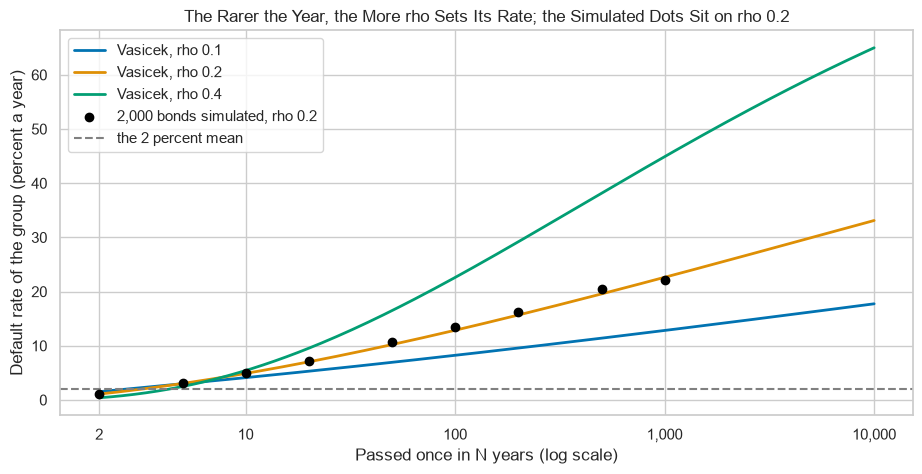

In [29]:
# the rate passed once in N years under these invented inputs, Vasicek at three rho, the 2,000 bonds' scenarios as dots
N = np.logspace(np.log10(2), 4, 200)
plt.figure(figsize=(11, 5))
for rho in [0.1, 0.2, 0.4]:
    plt.plot(N, 100 * vasicek_quantile(0.02, rho, 1 - 1 / N), linewidth=2, label=f"Vasicek, rho {rho}")
N_dots = np.array([2, 5, 10, 20, 50, 100, 200, 500, 1000])
plt.scatter(N_dots, 100 * np.quantile(group_rates, 1 - 1 / N_dots), color="black", zorder=3, label="2,000 bonds simulated, rho 0.2")
plt.axhline(2, color="gray", linestyle="--", label="the 2 percent mean")
plt.xscale("log")
plt.xticks([2, 10, 100, 1_000, 10_000], ["2", "10", "100", "1,000", "10,000"])
plt.xlabel("Passed once in N years (log scale)")
plt.ylabel("Default rate of the group (percent a year)")
plt.title("The Rarer the Year, the More rho Sets Its Rate; the Simulated Dots Sit on rho 0.2")
plt.legend()
plt.show()

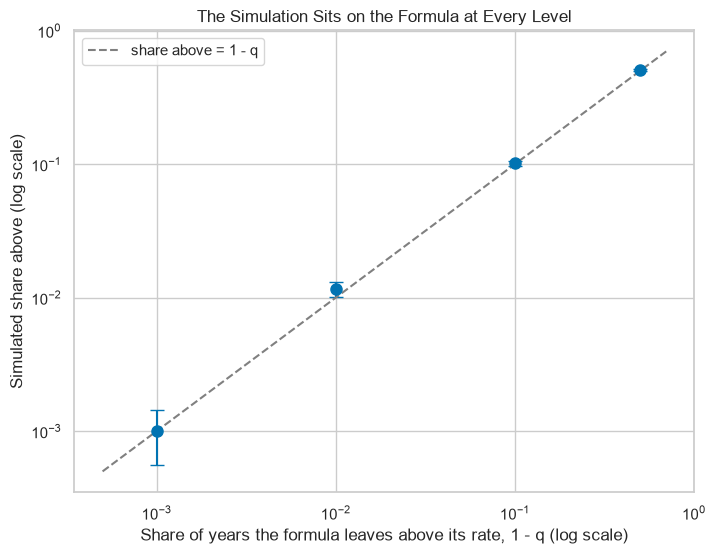

In [30]:
# the shares above the formula with 1.96 standard-error whiskers, against the share each level should leave above
plt.figure(figsize=(8, 6))
plt.errorbar(vasicek_check["should be"], vasicek_check["share above"], yerr=1.96 * vasicek_check["standard error"], fmt="o", capsize=5, markersize=8)
plt.plot([0.0005, 0.7], [0.0005, 0.7], color="gray", linestyle="--", label="share above = 1 - q")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Share of years the formula leaves above its rate, 1 - q (log scale)")
plt.ylabel("Simulated share above (log scale)")
plt.title("The Simulation Sits on the Formula at Every Level")
plt.legend()
plt.show()

Every simulated share lies within about two standard errors of 1 - q; at 0.99 it sits about two high, as 2,000 bonds are many but not infinite.

> STORY: In July 2005 the Basel Committee on Banking Supervision published a note on its formulas for the capital that banks hold against unexpected credit losses.
> It builds them on Merton (1974) and Vasicek (2002), with a normal distribution for the common and the own factors.
> The default threshold is the inverse normal of the average PD, and the common factor is set at its 99.9 percent point: the formula of the cell above.
> The note fixes the confidence level at 99.9 percent and sets the corporate asset correlation between two limits, 12 and 24 percent, lower as the PD rises.
> Source: Basel Committee on Banking Supervision, "An Explanatory Note on the Basel II IRB Risk Weight Functions", July 2005, pages 5, 6 and 11 to 13, https://www.bis.org/bcbs/irbriskweight.htm

**A once-in-a-thousand-years rate is set by rho as much as by the average.**

# The Book's Loss Distribution

## 50,000 Scenarios of the Book

The **loss distribution** is the spread of the book's credit loss over the scenarios.
`RHO` is an input chosen for the lesson, and each defaulted bond's LGD is drawn from Day 1's `rng.beta(6, 4)`, mean 0.60.

In [31]:
# the book's default probabilities and market values as arrays
default_prob = book["default_prob"].to_numpy()
mv = book["market_value"].to_numpy()
RHO = 0.20

# 50,000 scenarios: the defaults, an LGD for every bond, and each bond's loss in US$
rng = np.random.default_rng(SEED)
defaults = one_factor_defaults(default_prob, RHO, 50_000, rng)
lgd = rng.beta(6, 4, defaults.shape)
bond_losses = defaults * lgd * mv
losses = bond_losses.sum(axis=1)

In [32]:
# the mean loss with Day 1's standard error, against the expected loss
print(f"Mean loss: US${losses.mean():,.0f} (standard error US${losses.std(ddof=1) / np.sqrt(len(losses)):,.0f}) | expected loss US${book['expected_loss'].sum():,.0f}")
none = losses == 0
print(f"No default in {100 * none.mean():.1f} percent of scenarios (standard error {100 * none.std(ddof=1) / np.sqrt(len(none)):.1f}) | most defaults in one scenario: {defaults.sum(axis=1).max()}")

Mean loss: US$3,473,241 (standard error US$20,445) | expected loss US$3,482,412
No default in 29.2 percent of scenarios (standard error 0.2) | most defaults in one scenario: 50


## Credit VaR and Expected Shortfall

Day 2's `var_es`, repeated: on credit losses it gives the **credit VaR** and its expected shortfall.
The **unexpected loss** is the VaR less the mean loss.

In [33]:
# Day 2's VaR and expected shortfall of a series of losses, a loss positive
def var_es(loss, level):
    """VaR and expected shortfall of a series of losses, a loss positive."""
    var = np.quantile(loss, level)
    return var, loss[loss >= var].mean()

# the book's credit VaR, expected shortfall and unexpected loss in US$ m at three levels
levels = {}
for level in [0.95, 0.99, 0.999]:
    var, es = var_es(losses, level)
    levels[level] = {"VaR": var, "ES": es, "unexpected loss": var - losses.mean()}
(pd.DataFrame(levels).T / 1e6).round(2)

,VaR,ES,unexpected loss
0.950,12.37,17.76,8.90
0.990,20.74,26.98,17.26
0.999,35.22,41.94,31.75


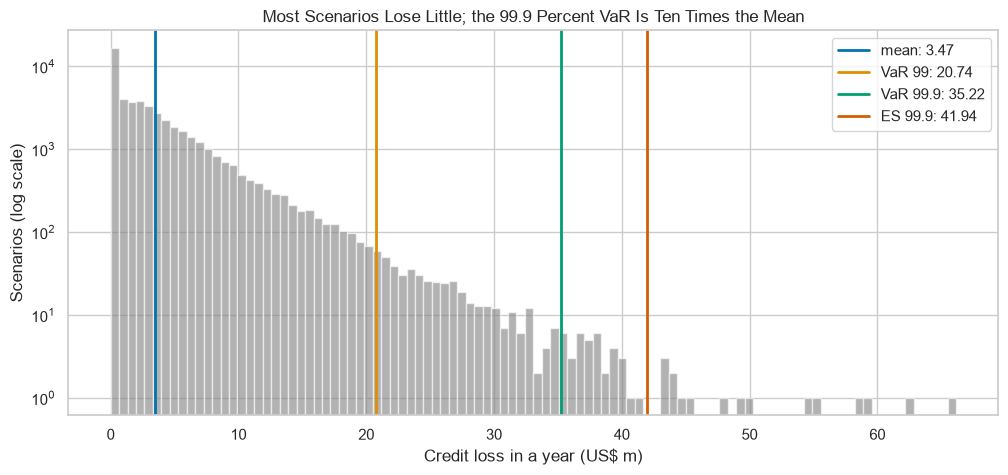

In [34]:
# the loss distribution on a log axis, the mean and the 99 and 99.9 percent VaR and ES marked
var_99, es_99 = var_es(losses, 0.99)
var_999, es_999 = var_es(losses, 0.999)
plt.figure(figsize=(12, 5))
plt.hist(losses / 1e6, bins=100, color="gray", alpha=0.6)
for value, name, colour in [(losses.mean(), "mean", "C0"), (var_99, "VaR 99", "C1"), (var_999, "VaR 99.9", "C2"), (es_999, "ES 99.9", "C3")]:
    plt.axvline(value / 1e6, color=colour, linewidth=2, label=f"{name}: {value / 1e6:.2f}")
plt.yscale("log")
plt.xlabel("Credit loss in a year (US$ m)")
plt.ylabel("Scenarios (log scale)")
plt.title("Most Scenarios Lose Little; the 99.9 Percent VaR Is Ten Times the Mean")
plt.legend()
plt.show()

Under these fitted default probabilities, this invented correlation and this invented LGD, the 99.9 percentile of a year's credit loss was US$35.22m and the average beyond it US$41.94m.

The unexpected loss at 99.9 percent, US$31.75m, is nine times the mean.

## How Sure the 99.9 Percent Loss Is

The 99.9 percent VaR rests on the worst 50 of 50,000 scenarios, and Day 1's standard error covers a mean only.
Ten runs, each from its own child of SEED, show how far a percentile moves between runs.

In [35]:
# one run of the book: 50,000 scenarios at a correlation, with beta(a, b) LGDs, in US$
def simulate_book(rho, rng, a=6, b=4):
    """The book's credit loss in each of 50,000 scenarios, in US$."""
    defaults = one_factor_defaults(default_prob, rho, 50_000, rng)
    return (defaults * rng.beta(a, b, defaults.shape) * mv).sum(axis=1)

# ten runs at RHO from ten children of SEED: the mean, VaR and ES at 99 and 99.9 percent, in US$ m
run_rows = []
for child in np.random.default_rng(SEED).spawn(10):
    run = simulate_book(RHO, child)
    run_rows.append({"mean": run.mean(), "VaR 99": var_es(run, 0.99)[0], "ES 99": var_es(run, 0.99)[1],
                     "VaR 99.9": var_es(run, 0.999)[0], "ES 99.9": var_es(run, 0.999)[1]})
runs = pd.DataFrame(run_rows) / 1e6
runs.agg(["min", "max", "std"]).round(3)

,mean,VaR 99,ES 99,VaR 99.9,ES 99.9
min,3.458,20.476,26.730,33.260,39.807
max,3.517,20.918,27.209,35.962,42.880
std,0.017,0.138,0.143,0.908,0.917


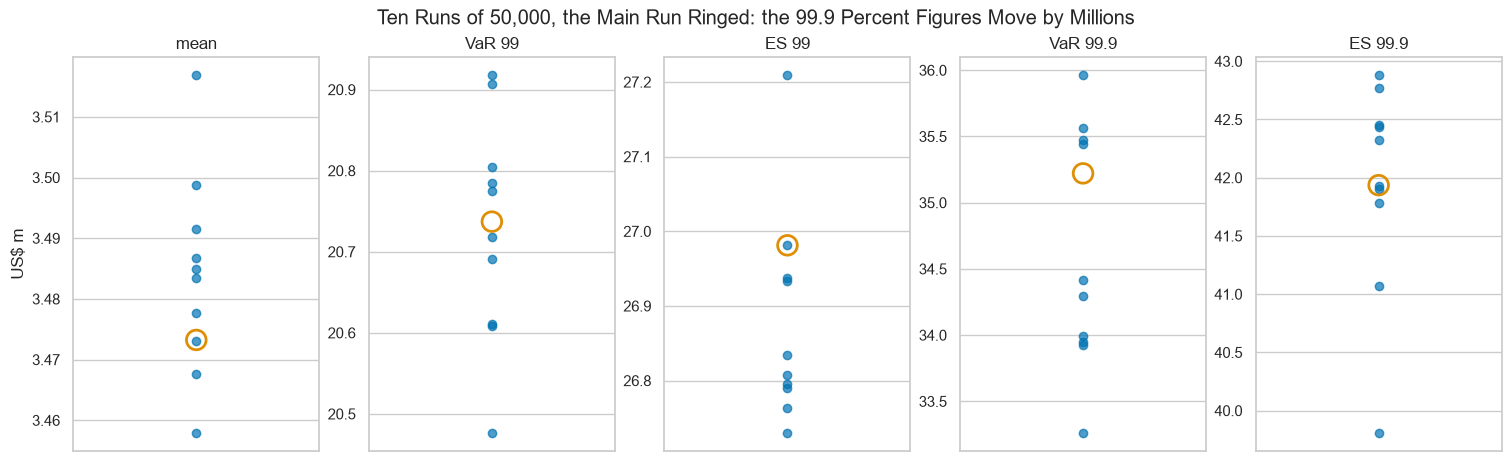

In [36]:
# the ten runs as strips, the main run ringed
fig, axes = plt.subplots(1, 5, figsize=(15, 4.5), layout="constrained")
main = {"mean": losses.mean(), "VaR 99": var_99, "ES 99": es_99, "VaR 99.9": var_999, "ES 99.9": es_999}
for ax, name in zip(axes, runs.columns):
    ax.scatter(np.zeros(10), runs[name], color="C0", alpha=0.7)
    ax.scatter(0, main[name] / 1e6, s=200, facecolors="none", edgecolors="C1", linewidths=2)
    ax.set(title=name, xticks=[], ylabel="US$ m" if name == "mean" else "")
fig.suptitle("Ten Runs of 50,000, the Main Run Ringed: the 99.9 Percent Figures Move by Millions")
plt.show()

The mean's spread over the ten runs, about US$17,000, sits close to the main run's standard error of US$20,445.

The 99.9 percent VaR ran from US$33.26m to US$35.96m, a standard deviation of US$0.91m; the main run, not one of the ten, sits inside.

At 99 percent the VaR's spread is US$0.14m.

**The 99.9 percent loss rests on 50 scenarios; read it to about a million dollars.**

# The Book's Tail

**Predict 5**

Investment grade holds 9.5 percent of the book's expected loss.

Q. What share of the loss in the worst 1 percent of scenarios is investment grade's? Write down a percent.

## Where the Worst 1 Percent Sits

In [37]:
# the worst 1 percent of scenarios, and investment grade's share of the loss there and on average
worst = losses >= var_99
ig = (book["grade"] == "Investment Grade").to_numpy()
print("Scenarios in the worst 1 percent:", worst.sum())
print(f"Investment grade: {100 * bond_losses[:, ig].sum() / bond_losses.sum():.1f} percent of the mean loss | {100 * bond_losses[worst][:, ig].sum() / bond_losses[worst].sum():.1f} percent of the worst 1 percent")
print(f"Investment grade defaults a scenario: {defaults[:, ig].sum(axis=1).mean():.2f} on average | {defaults[worst][:, ig].sum(axis=1).mean():.2f} in the worst 1 percent")

Scenarios in the worst 1 percent: 500
Investment grade: 9.4 percent of the mean loss | 19.7 percent of the worst 1 percent
Investment grade defaults a scenario: 0.22 on average | 3.36 in the worst 1 percent


In [38]:
# each bucket's share of the market value, of the mean loss and of the worst 1 percent's loss, in percent
tail_shares = pd.DataFrame({"market value": book.groupby("bucket")["market_value"].sum(),
                            "mean loss": pd.Series(bond_losses.sum(axis=0), index=book.index).groupby(book["bucket"]).sum(),
                            "worst 1 percent": pd.Series(bond_losses[worst].sum(axis=0), index=book.index).groupby(book["bucket"]).sum()}).loc[BUCKETS]
tail_shares = 100 * tail_shares / tail_shares.sum()
tail_shares.round(1)

,market value,mean loss,worst 1 percent
bucket,,,
AAA,1.7,0.0,0.1
AA,2.7,0.0,0.1
A,30.3,1.8,4.5
BBB,30.8,7.6,15.0
BB,23.2,18.8,27.7
B,8.9,42.3,35.8
CCC,2.6,29.5,16.7


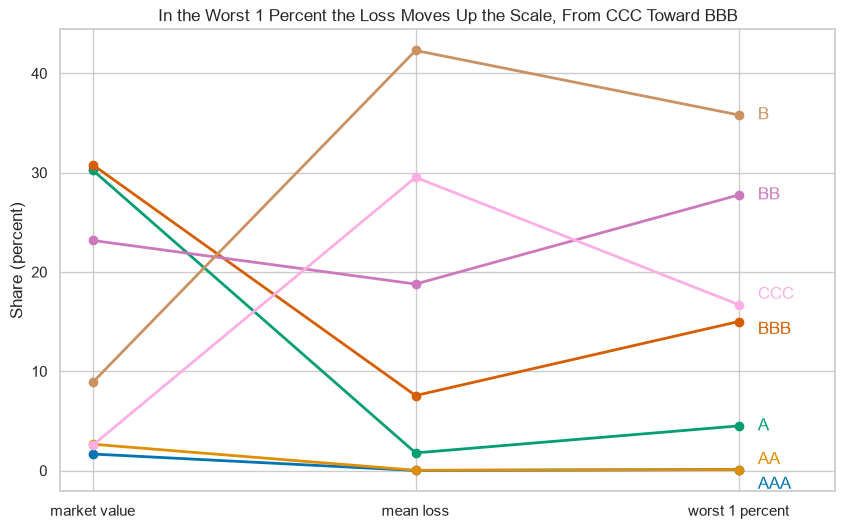

In [39]:
# the same shares as a slope chart: one line per bucket across the three columns
plt.figure(figsize=(10, 6))
nudge = {"AAA": -1.5, "AA": 1.0, "CCC": 1.0, "BBB": -0.8}
for i, bucket in enumerate(BUCKETS):
    plt.plot([0, 1, 2], tail_shares.loc[bucket], marker="o", linewidth=2, color=f"C{i}")
    plt.text(2.06, tail_shares.loc[bucket, "worst 1 percent"] + nudge.get(bucket, 0), bucket, va="center", color=f"C{i}")
plt.xticks([0, 1, 2], tail_shares.columns)
plt.xlim(-0.1, 2.3)
plt.ylabel("Share (percent)")
plt.title("In the Worst 1 Percent the Loss Moves Up the Scale, From CCC Toward BBB")
plt.show()

In the worst scenarios the common factor is bad for every bond, so bonds with low default probabilities default too.

## Your Turn: The Book at Any Correlation

Every slider position is a fresh run of 50,000 from the same seed, so 0.2 repeats the main run.

In [40]:
# the loss passed once in N years under these invented inputs, at any rho
def draw_book(rho=0.2):
    sim = simulate_book(rho, np.random.default_rng(SEED))
    N = np.logspace(np.log10(2), 3, 100)
    plt.figure(figsize=(11, 4.5))
    plt.plot(N, np.quantile(sim, 1 - 1 / N) / 1e6, linewidth=2)
    plt.scatter([100, 1000], [var_es(sim, 0.99)[0] / 1e6, var_es(sim, 0.999)[0] / 1e6], color="C1", zorder=3)
    plt.xscale("log")
    plt.xticks([2, 10, 100, 1_000], ["2", "10", "100", "1,000"])
    plt.ylim(0, 70)
    plt.xlabel("Passed once in N years (log scale)")
    plt.ylabel("Credit loss (US$ m)")
    # a dollar sign is written \$ in a chart title, as two of them would start a formula
    plt.title(f"rho {rho:.2f}: Passed Once in 100 Years US\\${var_es(sim, 0.99)[0] / 1e6:.1f}m, Once in 1,000 US\\${var_es(sim, 0.999)[0] / 1e6:.1f}m")
    plt.show()

In [41]:
# your turn: move rho and watch the tail
interact(draw_book, rho=(0.0, 0.4, 0.05));

interactive(children=(FloatSlider(value=0.2, description='rho', max=0.4, step=0.05), Output()), _dom_classes=(…

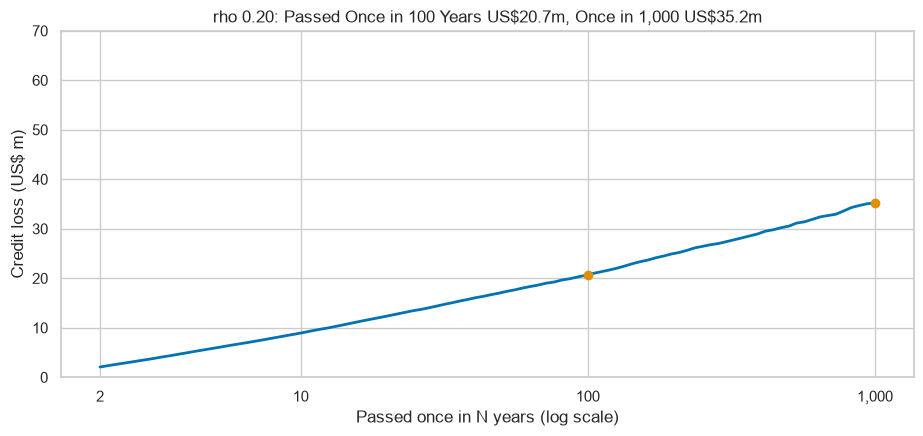

In [42]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_book(rho=0.2)

## Correlation Against the LGD

In [43]:
# four correlations with beta(6, 4) LGDs, each run from its own child of SEED
settings = {}
for rho, child in zip([0.0, 0.1, 0.2, 0.3], np.random.default_rng(SEED).spawn(4)):
    settings[f"rho {rho}"] = simulate_book(rho, child)

# four LGD spreads at RHO, all with mean 0.6, from four fresh children of SEED: one fixed, three beta draws
lgd_children = np.random.default_rng(SEED).spawn(4)
settings["LGD fixed at 0.6"] = (one_factor_defaults(default_prob, RHO, 50_000, lgd_children[0]) * 0.6 * mv).sum(axis=1)
for (a, b), child in zip([(12, 8), (6, 4), (3, 2)], lgd_children[1:]):
    settings[f"LGD beta({a}, {b})"] = simulate_book(RHO, child, a, b)

# the mean and 99.9 percent VaR in US$ m, and the share of scenarios with no default
setting_rows = {}
for name, setting_losses in settings.items():
    setting_rows[name] = {"mean": setting_losses.mean(), "VaR 99.9": var_es(setting_losses, 0.999)[0], "none (%)": 100 * (setting_losses == 0).mean()}
setting_table = pd.DataFrame(setting_rows).T
(setting_table / [1e6, 1e6, 1]).round(2)

,mean,VaR 99.9,none (%)
rho 0.0,3.49,14.42,8.76
rho 0.1,3.49,23.15,19.74
rho 0.2,3.48,34.29,29.44
rho 0.3,3.47,49.26,37.56
LGD fixed at 0.6,3.51,33.91,28.91
"LGD beta(12, 8)",3.49,35.77,29.12
"LGD beta(6, 4)",3.48,34.29,29.44
"LGD beta(3, 2)",3.47,35.38,29.42


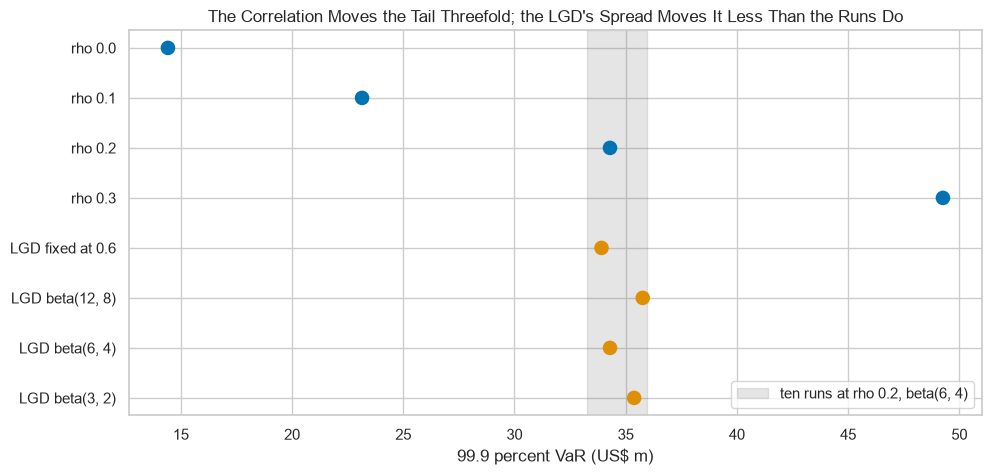

In [44]:
# the 99.9 percent VaR at each setting, the ten runs' range shaded
plt.figure(figsize=(11, 5))
plt.axvspan(runs["VaR 99.9"].min(), runs["VaR 99.9"].max(), color="gray", alpha=0.2, label="ten runs at rho 0.2, beta(6, 4)")
plt.scatter(setting_table["VaR 99.9"] / 1e6, setting_table.index, s=90, color=["C0"] * 4 + ["C1"] * 4, zorder=3)
plt.gca().invert_yaxis()
plt.xlabel("99.9 percent VaR (US$ m)")
plt.title("The Correlation Moves the Tail Threefold; the LGD's Spread Moves It Less Than the Runs Do")
plt.legend(loc="lower right")
plt.show()

From `rho` 0 to 0.3 the 99.9 percent VaR more than tripled while the mean stayed at US$3.5m.

Every LGD setting landed inside the ten runs' range: the LGD's spread barely moved the tail.

**The correlation sets the tail; the LGD's spread, under these inputs, hardly does.**

# Two Correlated Factors

## A Cholesky Factor

Two factors correlated 0.5 come from two independent draws mixed by a **Cholesky factor**: a lower-triangular L with L times its transpose equal to the correlation matrix.
`np.linalg.cholesky` finds it, if the matrix is **positive definite**: every mix of the factors has a variance above 0.

In [45]:
# the Cholesky factor of a 2 x 2 correlation matrix, and the check that L @ L.T gives it back
corr = np.array([[1.0, 0.5], [0.5, 1.0]])
L = np.linalg.cholesky(corr)
print(L.round(4))
print("L @ L.T equals corr:", np.allclose(L @ L.T, corr))

[[1.    0.   ]
 [0.5   0.866]]
L @ L.T equals corr: True


In [46]:
# 100,000 pairs of independent draws, mixed by L: their correlation and standard deviations
rng = np.random.default_rng(SEED)
pairs = rng.standard_normal((100_000, 2)) @ L.T
print("Correlation:", round(np.corrcoef(pairs.T)[0, 1], 4), "| standard deviations:", pairs.std(axis=0).round(3))

Correlation: 0.4957 | standard deviations: [0.999 1.004]


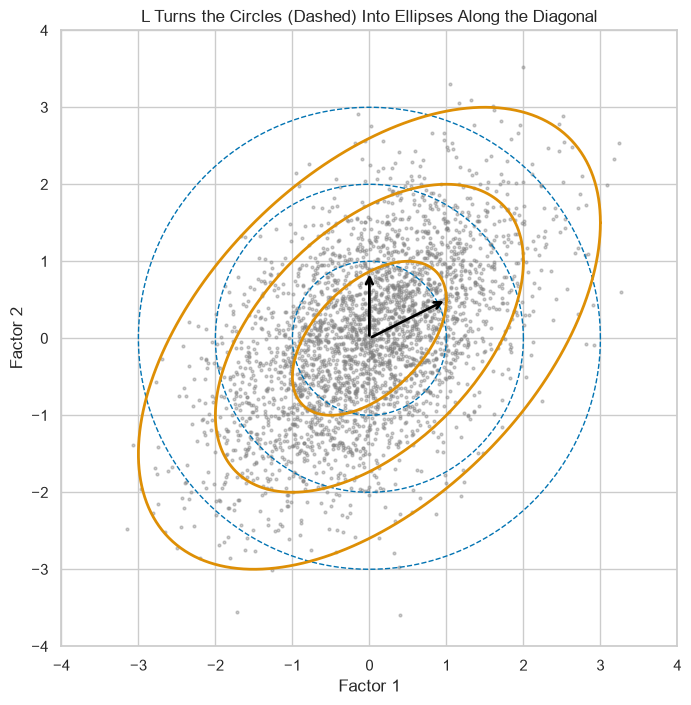

In [47]:
# the unit circle and its rings at 2 and 3, mapped by L (np.cos and np.sin trace a circle, np.pi is pi), L's columns as arrows
angle = np.linspace(0, 2 * np.pi, 200)
circle = np.column_stack([np.cos(angle), np.sin(angle)])
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(pairs[:3_000, 0], pairs[:3_000, 1], s=4, color="gray", alpha=0.4)
for r in [1, 2, 3]:
    ax.plot(*(r * circle).T, color="C0", linestyle="--", linewidth=1)
    ax.plot(*(r * circle @ L.T).T, color="C1", linewidth=2)
for column in L.T:
    ax.annotate("", xy=column, xytext=(0, 0), arrowprops={"arrowstyle": "->", "color": "black", "linewidth": 2})
# set_aspect("equal") gives both axes the same scale, so a circle reads as a circle
ax.set_aspect("equal")
ax.set(xlim=(-4, 4), ylim=(-4, 4), xlabel="Factor 1", ylabel="Factor 2", title="L Turns the Circles (Dashed) Into Ellipses Along the Diagonal")
plt.show()

L's first column, (1, 0.5), tilts the circle onto the diagonal, and its second, (0, 0.866), keeps the second factor's spread at 1.

## Two Halves of the Book

The sectors in alphabetical order split the book in two, a split chosen for the lesson: each half takes its own factor, the two correlated 0.5.

In [48]:
# each bond's factor column: 0 for the first five sectors in alphabetical order, 1 for the other five
sectors = sorted(book["sector"].unique())
half = np.where(book["sector"].isin(sectors[:5]), 0, 1)
print("Bonds on factor 0:", (half == 0).sum(), "| on factor 1:", (half == 1).sum())

# two factors correlated through L; factors[:, half] gives each bond its half's column (Course 1's list of positions)
two, one = np.random.default_rng(SEED).spawn(2)
factors = two.standard_normal((50_000, 2)) @ L.T
own = two.standard_normal((50_000, len(book)))
two_defaults = np.sqrt(RHO) * factors[:, half] + np.sqrt(1 - RHO) * own < stats.norm.ppf(default_prob)
two_losses = (two_defaults * two.beta(6, 4, two_defaults.shape) * mv).sum(axis=1)

# the 99 percent VaR in US$ m on two factors, on one factor from its own child, and the main run's
print(f"99 percent VaR: two factors US${var_es(two_losses, 0.99)[0] / 1e6:.2f}m | one factor US${var_es(simulate_book(RHO, one), 0.99)[0] / 1e6:.2f}m | main run US${var_99 / 1e6:.2f}m")

Bonds on factor 0: 109 | on factor 1: 91
99 percent VaR: two factors US$18.48m | one factor US$20.61m | main run US$20.74m


Two factors that do not move as one lower the 99 percent VaR by about US$2.1m, far beyond the runs' spread of US$0.14m.

The one-factor figure comes from its own child of SEED, so it differs a little from the main run's; both sit inside the ten runs.

## A Matrix Typed by Hand

A matrix is positive definite when all its **eigenvalues**, the variances of its independent mixes, are above 0; `np.linalg.eigvalsh` lists them.

In [49]:
# three correlations typed one pair at a time, and the matrix's eigenvalues
corr_bad = np.array([[1.0, 0.9, -0.6], [0.9, 1.0, 0.4], [-0.6, 0.4, 1.0]])
eigenvalues = np.linalg.eigvalsh(corr_bad)
print("Eigenvalues:", eigenvalues.round(4))

# with 0.9 and -0.6 fixed, the range the third correlation must lie in
low = 0.9 * -0.6 - np.sqrt((1 - 0.9 ** 2) * (1 - 0.6 ** 2))
high = 0.9 * -0.6 + np.sqrt((1 - 0.9 ** 2) * (1 - 0.6 ** 2))
print(f"The third correlation must lie between {low:.3f} and {high:.3f}; it was typed as 0.4")

Eigenvalues: [-0.2903  1.3598  1.9304]
The third correlation must lie between -0.889 and -0.191; it was typed as 0.4


In [50]:
# Cholesky of a matrix with a negative eigenvalue
np.linalg.cholesky(corr_bad)

LinAlgError: Matrix is not positive definite

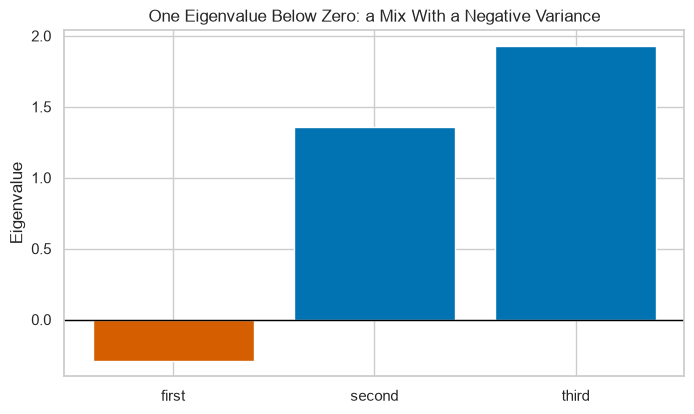

In [51]:
# the eigenvalues as bars, the negative one coloured
plt.figure(figsize=(8, 4.5))
plt.bar(["first", "second", "third"], eigenvalues, color=["C3" if e < 0 else "C0" for e in eigenvalues])
plt.axhline(0, color="black", linewidth=1)
plt.ylabel("Eigenvalue")
plt.title("One Eigenvalue Below Zero: a Mix With a Negative Variance")
plt.show()

**Correlations typed one pair at a time can contradict each other; the error is the check.**

# Insights and Conclusion

AAA and AA counted no default, and AAA's 168 firm-years capped its rate only at 1.77 percent a year.

One logistic slope, odds 1.64 times as high a notch, gave every bond a default probability.

Years 10, 11 and 12 left the independent band, and the squared gaps averaged 2.17 against about 1 under independence.

Correlation kept the mean at 2 defaults in 100 and moved the share of years with none from 13 to 56 percent.

The Vasicek formula held against 2,000 simulated bonds at every level.

The book's 99.9 percent credit VaR, US$35.2m to about a million dollars, is ten times its expected loss, and investment grade's share of the tail is twice its share of the mean.

`rho` tripled the tail; the LGD's spread barely moved it; Cholesky works only on a true correlation matrix.

**The default rates set the average year; the correlation sets the bad ones.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Count default rates per firm-year and bound a rate where none was counted.
* Fill thin buckets with a pooled logistic fit and give every bond a default probability.
* Set yearly default counts against the band independence allows.
* Simulate defaults through one common factor, and check the simulation against the Vasicek formula.
* Read a credit VaR and expected shortfall with the spread of spawned runs, and find where the tail sits.
* Correlate factors with a Cholesky factor, and read a matrix's eigenvalues when it has none.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [52]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**A Lower Correlation**

Q. Store the Vasicek default rate passed once in 1,000 years for a group at 1 percent a year and `rho` 0.12 in `ex1_rate`, as a fraction.

In [53]:
# the lesson's vasicek_quantile at 1 percent, rho 0.12 and the 99.9 percent level
ex1_rate = vasicek_quantile(0.01, 0.12, 0.999)
print(f"{100 * ex1_rate:.2f} percent a year | {ex1_rate / 0.01:.1f} times the 1 percent mean | at rho 0.2: {100 * vasicek_quantile(0.01, 0.2, 0.999):.2f} percent")

9.03 percent a year | 9.0 times the 1 percent mean | at rho 0.2: 14.55 percent


At `rho` 0.12 the once-in-1,000-years rate is about nine times the mean.

In [54]:
check("Exercise 1 the Vasicek rate at 1 percent and 0.12", ex1_rate, 0.09032583132606531)

Exercise 1 the Vasicek rate at 1 percent and 0.12: correct


### Exercise 2

**The Chance of a Bad Year**

The chance that a very large group's default rate passes x is the Vasicek formula turned around: `stats.norm.cdf((np.sqrt(1 - rho) * stats.norm.ppf(x) - stats.norm.ppf(default_prob)) / np.sqrt(rho))` is the chance it stays at or below x.

Q. Write `vasicek_cdf(x, default_prob, rho)`, which returns that chance, and show it gives back 0.5, 0.9 and 0.999 at `vasicek_quantile`'s rates. Store the chance that a group at 2 percent and `rho` 0.2 passes 10 percent in `ex2_above_10`.

In [55]:
# the chance the group's default rate stays at or below x
def vasicek_cdf(x, default_prob, rho):
    """The chance a very large group's default rate stays at or below x."""
    return stats.norm.cdf((np.sqrt(1 - rho) * stats.norm.ppf(x) - stats.norm.ppf(default_prob)) / np.sqrt(rho))

# it undoes vasicek_quantile, and gives the chance of passing 10 percent
print("Gives back:", [round(float(vasicek_cdf(vasicek_quantile(0.02, 0.2, q), 0.02, 0.2)), 6) for q in [0.5, 0.9, 0.999]])
ex2_above_10 = 1 - vasicek_cdf(0.10, 0.02, 0.2)
print(f"Chance of passing 10 percent: {ex2_above_10:.6f}, about once in {1 / ex2_above_10:.0f} years")

Gives back: [0.5, 0.9, 0.999]
Chance of passing 10 percent: 0.021218, about once in 47 years


The two functions undo each other, as a `cdf` and a `ppf` do.

In [56]:
check("Exercise 2 the chance of passing 10 percent", ex2_above_10, 0.021217992460147328)

Exercise 2 the chance of passing 10 percent: correct


### Exercise 3

**A Student's t Copula**

A **t copula** divides each scenario's mix by sqrt(W / 4), with W one `rng.chisquare(4, (50_000, 1))` draw a scenario shared by every bond, and sets the threshold at Day 2's `stats.t.ppf(0.02, 4)`.

Q. With one generator from SEED, draw the common factor `(50_000, 1)`, the own factors `(50_000, 100)`, then W, for 100 bonds at 2 percent and `rho` 0.2. Store the share of scenarios with 10 or more defaults in `ex3_share`.

In [57]:
# the common factor, the own factors, then one W a scenario, in that order from one generator
rng = np.random.default_rng(SEED)
common = rng.standard_normal((50_000, 1))
own = rng.standard_normal((50_000, 100))
w = rng.chisquare(4, (50_000, 1))

# the mix divided by sqrt(W / 4), against the t's 2 percent point
t_counts = ((np.sqrt(0.2) * common + np.sqrt(0.8) * own) / np.sqrt(w / 4) < stats.t.ppf(0.02, 4)).sum(axis=1)
ex3_share = np.mean(t_counts >= 10)
print(f"Mean {t_counts.mean():.3f} | none {100 * np.mean(t_counts == 0):.1f} percent | 10 or more {100 * ex3_share:.3f} percent, against {table.loc[0.2, '10 or more (%)']:.3f} for the normal")

Mean 2.025 | none 67.5 percent | 10 or more 6.296 percent, against 3.098 for the normal


The mean stays at 2, while the shared W pushes every bond toward default in the same scenarios: more years with none and about twice as many with 10 or more.

In [58]:
check("Exercise 3 the t copula's share with 10 or more", ex3_share, 0.06296)

Exercise 3 the t copula's share with 10 or more: correct


### Exercise 4: AI check

**Correlated in Name Only**

You asked an AI assistant for a function that draws correlated defaults.
This came back.
Test it against what you know, then find the one bug.

In [59]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def correlated_defaults(default_prob, rho, n_sims, rng):
    """Defaults in each scenario for each bond, correlated through one common factor shared by every bond."""
    common = rng.standard_normal((n_sims, len(default_prob)))
    own = rng.standard_normal((n_sims, len(default_prob)))
    return np.sqrt(rho) * common + np.sqrt(1 - rho) * own < stats.norm.ppf(default_prob)

In [60]:
# 100 bonds at 2 percent and rho 0.3: the count's variance against the binomial's, n p (1 - p), which independence gives
rng = np.random.default_rng(SEED)
test_counts = correlated_defaults(np.full(100, 0.02), 0.3, 20_000, rng).sum(axis=1)
print("Variance of the count:", round(test_counts.var(ddof=1), 2), "| binomial's:", round(100 * 0.02 * 0.98, 2), "| share with 10 or more:", np.mean(test_counts >= 10))

Variance of the count: 1.96 | binomial's: 1.96 | share with 10 or more: 0.0


Q. Fix the one wrong line, rerun the test from a fresh generator, and store the share of the 20,000 scenarios with 10 or more defaults in `ex4_share`.

In [61]:
# the fix: one common draw a scenario, shape (n_sims, 1), shared by every bond
def correlated_defaults(default_prob, rho, n_sims, rng):
    """Defaults in each scenario for each bond, correlated through one common factor shared by every bond."""
    common = rng.standard_normal((n_sims, 1))
    own = rng.standard_normal((n_sims, len(default_prob)))
    return np.sqrt(rho) * common + np.sqrt(1 - rho) * own < stats.norm.ppf(default_prob)

rng = np.random.default_rng(SEED)
test_counts = correlated_defaults(np.full(100, 0.02), 0.3, 20_000, rng).sum(axis=1)
ex4_share = np.mean(test_counts >= 10)
print("Variance of the count:", round(test_counts.var(ddof=1), 2), "| share with 10 or more:", ex4_share)

Variance of the count: 14.59 | share with 10 or more: 0.0454


The planted line drew a fresh common factor for every bond, so each bond's draw was its own and the count's variance matched the binomial's: the docstring's shared factor was missing.

With one common draw a scenario the variance rises far above the binomial's, and scenarios with 10 or more defaults appear.

In [62]:
check("Exercise 4 the fixed share with 10 or more", ex4_share, 0.0454)

Exercise 4 the fixed share with 10 or more: correct


## Congratulations!

You turned a cohort of invented firms into a default probability for every bond, and saw why a bucket with no default still carries a rate.
You caught defaults arriving together, built the one-factor model that makes them do so, and checked it against Vasicek's formula.
Then you simulated the book's credit loss, read its tail with the honesty of ten runs, and found that the correlation, not the average, sets the bad years.
In Day 4 the cohort's firms are followed through time, and the exits that left today's file early get their due.

[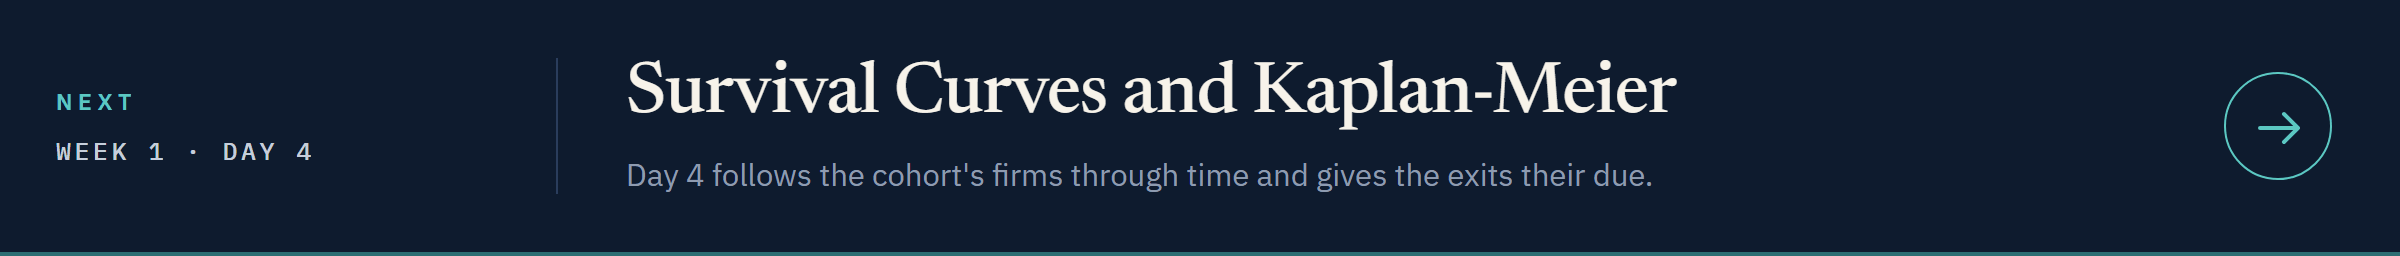](../day4/04_survival_curves_and_kaplan_meier.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week1/day4/04_survival_curves_and_kaplan_meier.ipynb)